In [ ]:
# JERICHON import bootstrap (shared resolver in src/project_paths.py)
from pathlib import Path
import os, sys

# Locate repository from the current working directory or its parents.
_candidates = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
for _base in list(_candidates):
    try:
        _candidates.extend(_child for _child in _base.iterdir() if _child.is_dir())
    except (OSError, PermissionError):
        pass
PROJECT_ROOT = next((p.resolve() for p in _candidates
                     if (p / "src" / "__init__.py").is_file()
                     and (p / "src" / "data" / "builders").is_dir()), None)
if PROJECT_ROOT is None:
    _env_root = os.environ.get("JERICHON_PROJECT_ROOT")
    if _env_root:
        _candidate = Path(_env_root).expanduser().resolve()
        if (_candidate / "src" / "__init__.py").is_file():
            PROJECT_ROOT = _candidate
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Не найден корень JERICHON. Откройте VS Code в папке репозитория "
        "или задайте JERICHON_PROJECT_ROOT.")
if str(PROJECT_ROOT) in sys.path:
    sys.path.remove(str(PROJECT_ROOT))
sys.path.insert(0, str(PROJECT_ROOT))
from src.project_paths import bootstrap_project, find_project_root
PROJECT_ROOT = bootstrap_project(PROJECT_ROOT)


# JERICHON — Research 02: рыночные режимы, специализированные модели и аудит сделок

## Цель эксперимента

Проверить, улучшает ли **адаптивная стратегия с отдельной CatBoost-моделью для каждого рыночного режима** торговый результат относительно одной общей модели.

Внутри ноутбука:
1. Загружается локальная AlgoPack-история и строятся Dollar Bars + полный набор причинных признаков, как в `jerichon_mark_63(7).ipynb`.
2. Строятся CUSUM + Triple Barrier labels; `TIME` исключается из классификации, классы — `DOWN=0`, `UP=1`.
3. Кластеризатор режимов обучается **только на train**. Масштабирование, импутация и PCA также fit только на train.
4. Сравниваются глобальная модель и модели, обученные на событиях каждого кластера. Если в режиме мало данных/один класс, используется глобальная модель — это явно отражается в отчёте.
5. Сигналы оцениваются через существующий `for_ml.backtesting.backtest_engine`, включая комиссии, проскальзывание и правила исполнения проекта.
6. Выполняется аудит сделок: режим, направление, часы, длительность, причина выхода, прибыль/убыток, комиссии, серии убытков, MAE/MFE (если движок отдаёт нужные данные), а также анализ результатов по режимам.
7. Дополнительно сравниваются простые правила торговли вероятностным сигналом: порог входа и пропуск слабых сигналов. Это **диагностика на holdout**, не разрешение подбирать параметры по holdout.

**Важно:** notebook строит независимый эксперимент; он не меняет исходный notebook, модели или движок. Исходные данные читаются локально, API не вызывается. Перед запуском проверь путь репозитория в `find_project_root()` и установленную версию `backtest_engine.py`.


## Подготовка локальной истории и 474 причинных признаков

Ниже повторно используется проверенная подготовительная часть из базового notebook. Она читает локальные AlgoPack-файлы и строит Dollar Bars, Super Candle признаки, provenance и Triple Barrier labels. Блок оптимизации Optuna и сохранения новой модели сюда намеренно не перенесены.

In [1]:
# 0. CONFIG + IMPORTS
from pathlib import Path
import sys, inspect, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mplcyberpunk
plt.style.use('cyberpunk')
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, classification_report, confusion_matrix)

TICKER = "SMLT"                  # поменяй тикер при необходимости
DOLLAR_THRESHOLD = 10_000_000   # порог из reference notebook jerichon_mark_63(3)
MSK = "Europe/Moscow"
# Historical labels: CUSUM events + Triple Barrier (not fixed-horizon return labels).
CUSUM_THRESHOLD = 0.001
PT_SL = (2.4, 1.5)              # (take-profit multiplier, stop-loss multiplier); intentionally asymmetric
VERTICAL_HORIZON = 50           # vertical barrier in Dollar Bars
TARGET_WINDOW = 55              # volatility estimate window for Triple Barrier
EXPECTED_FEATURES = 474

# Автоматически ищем корень репозитория JERICHON, не фиксируем путь конкретного пользователя.
def find_project_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    candidates = [start, *start.parents]
    for p in candidates:
        if (p / "data" / "for_ml" / "storage" / "history").exists() and (p / "src" / "data" / "builders").exists():
            return p
    raise FileNotFoundError(
        "Не найден корень JERICHON. Открой notebook из папки репозитория "
        "или укажи PROJECT_ROOT вручную."
    )

ROOT = PROJECT_ROOT / "data"
if str(ROOT.parent) not in sys.path:
    sys.path.insert(0, str(ROOT.parent))
HISTORY_ROOT = ROOT / "for_ml" / "storage" / "history"

from src.data.builders.dollar_bars import InformationDrivenBars
from src.data.builders.micro_features import MicroFeatures
from src.data.builders.build_features import FeatureBuilder
from src.data.builders import jerichon_feature_pipeline as jfp
from src.backtesting.backtest_engine import (backtest_saved_catboost, BacktestConfig,)

print("Ticker       :", TICKER)
print("Pipeline     :", Path(inspect.getfile(jfp)).resolve())
print("Pipeline API :", [n for n in ("build_feature_dataset", "build_dollar_bars_from_trades", "_base", "_build_sc_features", "_choose_availability", "_attach_source") if hasattr(jfp, n)])

Ticker       : SMLT
Pipeline     : C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\builders\jerichon_feature_pipeline.py
Pipeline API : ['build_feature_dataset', 'build_dollar_bars_from_trades', '_base', '_build_sc_features', '_choose_availability', '_attach_source']


## 1. Загрузка локальной истории

Формат путей сохранён **как в `jerichon_mark_63(3).ipynb`**:

- `data/for_ml/storage/history/realtime/{TICKER}/{YYYY-MM-DD}/trades.parquet`
- `data/for_ml/storage/history/supercandles/{TICKER}/{YYYY-MM-DD}/{tradestats,obstats,orderstats}.parquet`

Файлы только читаются. Если какой-то источник отсутствует, notebook покажет это явно.

In [2]:
def available_dates(history_root, ticker):
    dates = set()
    for kind in ("realtime", "supercandles"):
        p = history_root / kind / ticker
        if p.exists():
            dates.update(x.name for x in p.iterdir() if x.is_dir())
    return sorted(d for d in dates if len(d) == 10 and d[4] == "-" and d[7] == "-")

def load_local_history(history_root, ticker):
    keys = ("candles", "trades", "orderbook", "tradestats", "obstats", "orderstats")
    frames = {k: [] for k in keys}
    dates = available_dates(history_root, ticker)

    if not dates:
        raise FileNotFoundError(f"Для {ticker} не найдены сохранённые даты в {history_root}")

    for day in dates:
        for key in ("candles", "trades", "orderbook"):
            p = history_root / "realtime" / ticker / day / f"{key}.parquet"
            if p.exists():
                try:
                    x = pd.read_parquet(p)
                    if not x.empty:
                        x = x.copy()
                        x["file_date"] = day
                        frames[key].append(x)
                except Exception as e:
                    print(f"WARNING: не удалось прочитать {p}: {e}")

        for key in ("tradestats", "obstats", "orderstats"):
            p = history_root / "supercandles" / ticker / day / f"{key}.parquet"
            if p.exists():
                try:
                    x = pd.read_parquet(p)
                    if not x.empty:
                        x = x.copy()
                        x["file_date"] = day
                        frames[key].append(x)
                except Exception as e:
                    print(f"WARNING: не удалось прочитать {p}: {e}")

    out = {k: (pd.concat(v, ignore_index=True) if v else pd.DataFrame()) for k, v in frames.items()}
    print(f"Saved dates discovered: {len(dates)}")
    print(f"Date range            : {dates[0]} → {dates[-1]}")
    print("\\nLocal rows:")
    display(pd.DataFrame({"source": list(out), "rows": [len(out[k]) for k in out]}))
    missing = [s for s in ("trades", "tradestats", "obstats", "orderstats") if out[s].empty]
    if missing:
        raise RuntimeError(f"Не хватает локальных источников: {missing}. API-запрос не будет выполняться.")
    return out, dates

data, SAVED_DATES = load_local_history(HISTORY_ROOT, TICKER)

Saved dates discovered: 16
Date range            : 2026-09-25 → 2026-10-23
\nLocal rows:


,source,rows
0,candles,14363
1,trades,664633
2,orderbook,320
3,tradestats,2898
4,obstats,2818
5,orderstats,2914


## 2. Построение Dollar Bars и 474 признаков

Используем подготовленный модуль `jerichon_feature_pipeline.py`, а не копируем его инженерный код в notebook. Важно: **не вызываем** публичный `build_feature_dataset()`, если он сам создаёт `AlgoPackProvider`; вместо этого вызываем локальные функции модуля над уже прочитанными DataFrame.

Если локальная версия модуля не содержит ожидаемые helper-функции, выполнение остановится с понятной ошибкой, а не отправит запрос в API.

In [3]:
# Сначала проверяем интерфейс установленного файла — никаких сетевых вызовов здесь нет.
required_helpers = (
    "_trades_for_bars",
    "build_dollar_bars_from_trades",
    "_base",
    "_build_sc_features",
    "_choose_availability",
    "_attach_source",
)
missing_helpers = [name for name in required_helpers if not hasattr(jfp, name)]
if missing_helpers:
    raise RuntimeError(
        "В установленном jerichon_feature_pipeline.py не найдены helper-функции: "
        f"{missing_helpers}. Проверь, что в проекте стоит актуальная версия pipeline. "
        "Этот notebook намеренно не переключается на API."
    )

print("Helper signatures:")
for name in required_helpers:
    print(f"  {name}{inspect.signature(getattr(jfp, name))}")

Helper signatures:
  _trades_for_bars(trades)
  build_dollar_bars_from_trades(trades, threshold=13000000)
  _base(bars)
  _build_sc_features(raw_sources, bars_for_features)
  _choose_availability(df, source_name)
  _attach_source(bars, feature_frame, raw_source, source)


In [4]:
# Dollar Bars: используем тот же денежный объём VALUE / PRICE, что и в reference.
bars = jfp.build_dollar_bars_from_trades(data["trades"], threshold=DOLLAR_THRESHOLD)
if bars is None or bars.empty:
    raise RuntimeError("Dollar Bar builder вернул пустой результат.")

# Унифицируем имя времени для последующих causal joins.
if "bar_ts" not in bars.columns:
    if "close_time" not in bars.columns:
        raise RuntimeError(f"В bars нет bar_ts/close_time. Колонки: {list(bars.columns)}")
    bars["bar_ts"] = pd.to_datetime(bars["close_time"], errors="coerce", utc=True)
else:
    bars["bar_ts"] = pd.to_datetime(bars["bar_ts"], errors="coerce", utc=True)

bars = (bars.dropna(subset=["bar_ts"])
             .sort_values("bar_ts")
             .drop_duplicates("bar_ts", keep="last")
             .reset_index(drop=True))

print("Dollar Bars:", len(bars))
print("Period:", bars["bar_ts"].min(), "→", bars["bar_ts"].max())
display(bars.head(3))

Dollar Bars: 2907
Period: 2026-09-25 04:03:05+00:00 → 2026-10-23 19:50:54+00:00


,open,high,low,close,volume,value,count,open_time,close_time,bar_ts
0,251.2,252.2,251.0,252.2,40061.0,10074986.8,213,2026-09-25 03:59:54+00:00,2026-09-25 04:03:05+00:00,2026-09-25 04:03:05+00:00
1,252.0,252.2,251.0,251.6,39783.0,10002697.0,247,2026-09-25 04:03:05+00:00,2026-09-25 04:16:20+00:00,2026-09-25 04:16:20+00:00
2,251.6,251.8,250.6,250.8,39850.0,10014918.2,274,2026-09-25 04:16:20+00:00,2026-09-25 04:33:18+00:00,2026-09-25 04:33:18+00:00


In [5]:
# Base 73 + Super Candle 401. Работаем через helper-функции pipeline.
base_raw = jfp._base(bars.copy())
if isinstance(base_raw, tuple):
    # Поддержка версий helper, возвращающих (features, metadata).
    base_raw = base_raw[0]
if not isinstance(base_raw, pd.DataFrame):
    raise TypeError(f"_base должен вернуть DataFrame, получено: {type(base_raw)}")

# Приводим base frame к контракту bar_ts + 73 числовых признака.
if "bar_ts" not in base_raw.columns:
    if "close_time" in base_raw.columns:
        base_raw = base_raw.rename(columns={"close_time": "bar_ts"})
    elif isinstance(base_raw.index, pd.DatetimeIndex):
        base_raw = base_raw.reset_index().rename(columns={base_raw.index.name or "index": "bar_ts"})
    elif "ts" in base_raw.columns:
        base_raw = base_raw.rename(columns={"ts": "bar_ts"})
    else:
        raise RuntimeError(f"Не найден временной ключ в _base output. Колонки: {list(base_raw.columns)[:25]}")

base_raw["bar_ts"] = pd.to_datetime(base_raw["bar_ts"], errors="coerce", utc=True)
base_raw = base_raw.dropna(subset=["bar_ts"]).sort_values("bar_ts").drop_duplicates("bar_ts", keep="last").reset_index(drop=True)

# _build_sc_features может возвращать feature_frames либо (feature_frames, groups).
# Адаптируем Dollar Bars к формату, ожидаемому pipeline.
bars_for_sc = bars.copy()

# В pipeline ожидаются ts и CLOSE.
if "ts" not in bars_for_sc.columns:
    if "bar_ts" in bars_for_sc.columns:
        bars_for_sc["ts"] = bars_for_sc["bar_ts"]
    elif "close_time" in bars_for_sc.columns:
        bars_for_sc["ts"] = bars_for_sc["close_time"]
    else:
        raise KeyError("В bars отсутствует временная колонка ts/bar_ts/close_time")

if "CLOSE" not in bars_for_sc.columns:
    if "close" in bars_for_sc.columns:
        bars_for_sc["CLOSE"] = bars_for_sc["close"]
    else:
        raise KeyError("В bars отсутствует цена закрытия CLOSE/close")

bars_for_sc["ts"] = pd.to_datetime(bars_for_sc["ts"], errors="coerce", utc=True)

bars_for_sc = (
    bars_for_sc.dropna(subset=["ts"])
    .sort_values("ts")
    .reset_index(drop=True))

sc_result = jfp._build_sc_features(data, bars_for_sc)

if isinstance(sc_result, tuple):
    feature_frames = sc_result[0]
    feature_groups = sc_result[1] if len(sc_result) > 1 else {}
else:
    feature_frames = sc_result
    feature_groups = {}

if not isinstance(feature_frames, dict):
    raise TypeError("_build_sc_features должен возвращать dict feature frames.")

print("Base output shape:", base_raw.shape)
print("Super Candle feature groups:", list(feature_frames))

Base output shape: (2907, 74)
Super Candle feature groups: ['tradestats', 'orderstats', 'obstats']


C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\builders\jerichon_feature_pipeline.py:77: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out[f"{c}_z{w}"] = (s - mean) / (std + 1e-12)
C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\builders\jerichon_feature_pipeline.py:78: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  out[f"{c}_ma{w}"] = mean
C:\Users\Сергей Кравцов\Desktop\Morgan Co\JERICHON\data\for_ml\builders\jerichon_feature_pipeline.py:71: PerformanceWarning: DataFrame is highly fragmented.  Thi

In [6]:
# Availability validation and causal joins, source by source.
# Helpers' outputs are inspected to support the current prepared module contract.
validated = {}
availability_diagnostics = []

for source in ("tradestats", "obstats", "orderstats"):
    if data[source].empty:
        raise RuntimeError(f"Локальный источник {source} пуст.")

    result = jfp._choose_availability(data[source].copy(), source)
    if isinstance(result, tuple):
        validated[source] = result[0]
        if len(result) > 1 and isinstance(result[1], pd.DataFrame):
            availability_diagnostics.append(result[1])
    else:
        validated[source] = result

print("Validated sources:")
for source, frame in validated.items():
    print(f"  {source:12s}: {len(frame):,} rows, columns={len(frame.columns)}")

if availability_diagnostics:
    display(pd.concat(availability_diagnostics, ignore_index=True))

Validated sources:
  tradestats  : 2,898 rows, columns=2
  obstats     : 2,818 rows, columns=2
  orderstats  : 2,914 rows, columns=2


In [7]:
# Normalize the bars frame for the pipeline's attach helper.
bar_frame = bars.copy()
if "bar_ts" not in bar_frame.columns:
    raise RuntimeError("bar_ts missing from Dollar Bars.")

# Resolve each raw source to the corresponding feature frame by name.
def resolve_feature_frame(source, frames):
    if source in frames:
        return frames[source]
    matches = [k for k in frames if source.lower() in str(k).lower()]
    if len(matches) == 1:
        return frames[matches[0]]
    raise RuntimeError(f"Не удалось однозначно сопоставить {source} с feature frame. Доступны: {list(frames)}")

causal = bar_frame.copy()
for source in ("tradestats", "obstats", "orderstats"):
    feature_frame = resolve_feature_frame(source, feature_frames)
    
    # ИСПРАВЛЕНО: правильный порядок аргументов + исходные данные вместо validated
    attached = jfp._attach_source(causal, feature_frame, data[source], source)
    
    # Поддержка helper, возвращающего либо изменённый frame, либо None in-place.
    if isinstance(attached, pd.DataFrame):
        causal = attached
    print(f"{source:12s} attached → {causal.shape}")

# Добавляем base features по точному bar_ts.
base_cols = [c for c in base_raw.columns if c != "bar_ts" and pd.api.types.is_numeric_dtype(base_raw[c])]
if len(base_cols) != 73:
    raise RuntimeError(f"Ожидалось 73 base features, найдено {len(base_cols)}.")

base_join = base_raw[["bar_ts"] + base_cols].copy()
base_join = base_join.rename(columns={c: f"base__{c}" for c in base_cols})
base_cols = [c for c in base_join.columns if c.startswith("base__")]

if "bar_ts" not in causal.columns:
    raise RuntimeError(f"После causal join нет bar_ts. Колонки: {list(causal.columns)[:30]}")

causal["bar_ts"] = pd.to_datetime(causal["bar_ts"], errors="coerce", utc=True)
base_join["bar_ts"] = pd.to_datetime(base_join["bar_ts"], errors="coerce", utc=True)
causal = causal.merge(base_join, on="bar_ts", how="left", validate="one_to_one")

# Identify features and provenance without admitting timestamps into X.
time_cols = {"bar_ts", "bar_ts_utc", "ts", "ts_utc", "close_time"}
provenance_cols = [
    c for c in causal.columns
    if c.endswith("__event_ts") or c.endswith("__available_at")
]
sc_prefixes = ("tradestats__", "obstats__", "orderstats__")
sc_feature_cols = [
    c for c in causal.columns
    if c.startswith(sc_prefixes)
    and c not in provenance_cols
    and pd.api.types.is_numeric_dtype(causal[c])
]
# Не включаем сырые OHLCV/служебные колонки из bars: только канонические 73 + 401.
feature_cols = base_cols + sc_feature_cols

if len(feature_cols) != EXPECTED_FEATURES:
    raise RuntimeError(
        f"Feature inventory mismatch: {len(feature_cols)} numeric ML features, expected {EXPECTED_FEATURES}. "
        "Не продолжаем обучение на непроверенной матрице."
    )

if len(feature_cols) != len(set(feature_cols)):
    raise RuntimeError("Есть дублирующиеся имена признаков.")

FINAL_DATASET = causal[["bar_ts"] + feature_cols + provenance_cols].copy()
FINAL_DATASET = FINAL_DATASET.sort_values("bar_ts").reset_index(drop=True)
X_raw = FINAL_DATASET[feature_cols].copy()

print("FINAL_DATASET:", FINAL_DATASET.shape)
print("Rows:", len(FINAL_DATASET))
print("ML features:", len(feature_cols))
print("Provenance columns:", len(provenance_cols))

tradestats   attached → (2907, 106)
obstats      attached → (2907, 244)
orderstats   attached → (2907, 417)
FINAL_DATASET: (2907, 481)
Rows: 2907
ML features: 474
Provenance columns: 6


## 3. Temporal audit

Проверяем `available_at <= bar_ts` и `event_ts <= bar_ts` для каждого источника. Признаки из будущего — блокирующая ошибка. Дубликаты/пропуски/бесконечности дальше рассматриваются отдельно.

In [8]:
temporal_rows = []
for source in ("tradestats", "obstats", "orderstats"):
    av_col = f"{source}__available_at"
    ev_col = f"{source}__event_ts"
    if av_col not in FINAL_DATASET.columns or ev_col not in FINAL_DATASET.columns:
        raise RuntimeError(f"Нет provenance для {source}: ожидались {av_col}, {ev_col}")

    av = pd.to_datetime(FINAL_DATASET[av_col], errors="coerce", utc=True)
    ev = pd.to_datetime(FINAL_DATASET[ev_col], errors="coerce", utc=True)
    bar_ts = pd.to_datetime(FINAL_DATASET["bar_ts"], errors="coerce", utc=True)

    bad_av = av.notna() & (av > bar_ts)
    bad_ev = ev.notna() & (ev > bar_ts)
    temporal_rows.append({
        "source": source,
        "bars": len(FINAL_DATASET),
        "availability_future_violations": int(bad_av.sum()),
        "event_future_violations": int(bad_ev.sum()),
        "availability_missing_pct": round(float(av.isna().mean() * 100), 3),
        "event_missing_pct": round(float(ev.isna().mean() * 100), 3),
    })

temporal_audit = pd.DataFrame(temporal_rows)
display(temporal_audit)

if temporal_audit[["availability_future_violations", "event_future_violations"]].to_numpy().sum() != 0:
    raise RuntimeError("TEMPORAL AUDIT FAILED: обнаружен look-ahead по provenance.")
print("TEMPORAL AUDIT: PASS")

,source,bars,availability_future_violations,event_future_violations,availability_missing_pct,event_missing_pct
0,tradestats,2907,0,0,0.000,0.000
1,obstats,2907,0,0,0.034,0.034
2,orderstats,2907,0,0,0.000,0.000


TEMPORAL AUDIT: PASS


## 4. Проверка качества признаков

Нулевые значения не удаляем автоматически. Важные показатели:
- `NaN` и `±inf` по каждому признаку;
- доля нулей (диагностика, не критерий удаления);
- константные признаки;
- полностью пустые признаки;
- дублирующиеся строки и timestamps.

Исходный `FINAL_DATASET` не перезаписывается. Для модели создаётся отдельная копия, в которой бесконечности переводятся в `NaN`; далее imputer обучается только на train.

In [9]:
X_num = X_raw.apply(pd.to_numeric, errors="coerce")
arr = X_num.to_numpy(dtype="float64", copy=True)
finite_mask = np.isfinite(arr)

quality = pd.DataFrame(index=X_num.columns)
quality["missing_pct"] = X_num.isna().mean() * 100
quality["positive_inf"] = np.isposinf(arr).sum(axis=0)
quality["negative_inf"] = np.isneginf(arr).sum(axis=0)
quality["zero_pct"] = (X_num.eq(0).mean() * 100)
quality["unique_values"] = X_num.nunique(dropna=True)
quality["all_missing"] = X_num.isna().all()
quality["constant_or_single_value"] = quality["unique_values"] <= 1
quality["non_finite_total"] = quality["positive_inf"] + quality["negative_inf"]

print("Rows:", len(X_num), "| features:", X_num.shape[1])
print("NaN cells:", int(X_num.isna().sum().sum()))
print("+inf cells:", int(np.isposinf(arr).sum()))
print("-inf cells:", int(np.isneginf(arr).sum()))
print("Zero cells (% of all feature cells):", round(float(X_num.eq(0).to_numpy().mean() * 100), 2))
print("Duplicate bar_ts:", int(FINAL_DATASET["bar_ts"].duplicated().sum()))
print("Duplicate feature rows:", int(X_num.duplicated().sum()))

print("\\nWorst missingness:")
display(quality.sort_values(["missing_pct", "non_finite_total"], ascending=False).head(30))

print("\\nFeatures with infinities:")
display(quality.loc[quality["non_finite_total"] > 0].sort_values("non_finite_total", ascending=False))

print("\\nConstant / all-missing features:")
display(quality.loc[quality["constant_or_single_value"] | quality["all_missing"]])

Rows: 2907 | features: 474
NaN cells: 1505
+inf cells: 0
-inf cells: 0
Zero cells (% of all feature cells): 0.92
Duplicate bar_ts: 0
Duplicate feature rows: 0
\nWorst missingness:


,missing_pct,positive_inf,negative_inf,zero_pct,unique_values,all_missing,constant_or_single_value,non_finite_total
tradestats__ts_flow_x_return_ret,16.649467,0,0,0.000000,936,False,False,0
tradestats__ts_vwap_b_s_bps_ret,15.789474,0,0,3.061576,1021,False,False,0
obstats__ob_val_imb_bbo_vs_deep_ret,1.891985,0,0,0.963192,1121,False,False,0
obstats__ob_vol_imb_bbo_vs_deep_ret,1.479188,0,0,0.963192,1083,False,False,0
tradestats__ts_trade_imbalance_ret,0.687994,0,0,0.000000,1383,False,False,0
orderstats__os_put_vwap_b_s_bps_ret,0.447196,0,0,0.034400,1398,False,False,0
orderstats__os_put_orders_imb_ret,0.309598,0,0,0.000000,1400,False,False,0
tradestats__ts_vwap_b_s_bps_z3,0.240798,0,0,0.378397,1387,False,False,0
tradestats__ts_vwap_b_s_bps_ma3,0.240798,0,0,0.068799,1383,False,False,0
tradestats__ts_vwap_b_s_bps_chg,0.206398,0,0,3.783970,1292,False,False,0


\nFeatures with infinities:


,missing_pct,positive_inf,negative_inf,zero_pct,unique_values,all_missing,constant_or_single_value,non_finite_total


\nConstant / all-missing features:


,missing_pct,positive_inf,negative_inf,zero_pct,unique_values,all_missing,constant_or_single_value,non_finite_total


In [10]:
# Separate ML copy: keep source dataset unchanged.
X_model = X_num.replace([np.inf, -np.inf], np.nan).copy()

# Remove only features that cannot carry information at all (all missing or constant).
drop_features = quality.index[quality["all_missing"] | quality["constant_or_single_value"]].tolist()
if drop_features:
    print("Removing non-informative columns from model copy:", len(drop_features))
    print(drop_features[:30])
    X_model = X_model.drop(columns=drop_features)

print("X_model shape:", X_model.shape)
print("Remaining NaN cells (to be handled by train-only imputer):", int(X_model.isna().sum().sum()))

# Optional strict stop for pathological data; does not delete rows.
if X_model.shape[1] == 0:
    raise RuntimeError("После удаления пустых/константных признаков не осталось признаков.")

X_model shape: (2907, 474)
Remaining NaN cells (to be handled by train-only imputer): 1505


## 5. CUSUM + Triple Barrier: бинарная цель UP/DOWN

Triple Barrier по-прежнему строит три исходные метки, чтобы диагностировать распределение событий:
- `+1` — первым достигнут верхний барьер (`UP`);
- `-1` — первым достигнут нижний барьер (`DOWN`);
- `0` — до вертикального барьера не достигнут ни один горизонтальный барьер (`TIME`).

**В модель `TIME` не попадает вообще.** После визуализации распределения остаются только события `UP` и `DOWN`, а целевая переменная кодируется как `DOWN=0`, `UP=1`. Train/holdout делятся хронологически, пересекающие границу исходы purged.

CUSUM + TRIPLE BARRIER
CUSUM threshold : 0.001
PT_SL           : (2.4, 1.5) (TP multiplier, SL multiplier)
Vertical horizon: 50 Dollar Bars
Target window   : 55
CUSUM events    : 1,930
Triple Barrier events: 1,929
Raw labels: -1=DOWN, 0=TIME, +1=UP
  DOWN :   1,192 ( 61.79%)
  TIME :       6 (  0.31%)
  UP   :     731 ( 37.90%)


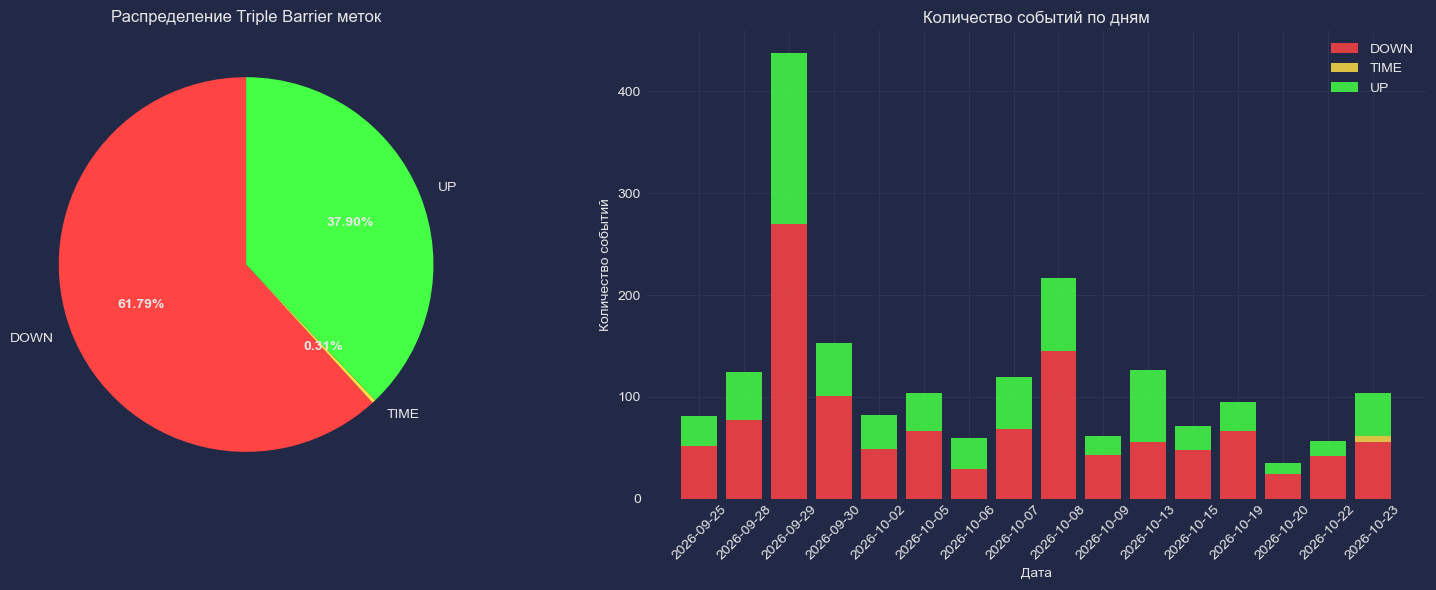


Aligned events before excluding TIME: 1,929
label
-1    1192
 0       6
 1     731
Name: count, dtype: int64


In [11]:
# =============================================================================
# LABELS: CUSUM → TRIPLE BARRIER → EVENT-ALIGNED X/y → BINARY TARGET
# =============================================================================
from src.data.labeling.cusum import cusum_filter
from src.data.labeling.triple_barrier import triple_barrier_labeling

# Use exactly the Dollar Bars that produced FINAL_DATASET.
bars_for_labeling = bars.copy()
if "bar_ts" not in bars_for_labeling.columns:
    raise RuntimeError(f"В bars отсутствует bar_ts. Колонки: {list(bars_for_labeling.columns)}")

rename_map = {
    "open": "OPEN", "high": "HIGH", "low": "LOW", "close": "CLOSE",
    "OPEN": "OPEN", "HIGH": "HIGH", "LOW": "LOW", "CLOSE": "CLOSE",
}
bars_for_labeling = bars_for_labeling.rename(columns=rename_map)
required_ohlc = ["HIGH", "LOW", "CLOSE"]
missing_ohlc = [c for c in required_ohlc if c not in bars_for_labeling.columns]
if missing_ohlc:
    raise RuntimeError(f"Для Triple Barrier не хватает OHLC-колонок: {missing_ohlc}")

bars_for_labeling["bar_ts"] = pd.to_datetime(
    bars_for_labeling["bar_ts"], errors="coerce", utc=True
)
bars_for_labeling = (
    bars_for_labeling.dropna(subset=["bar_ts"] + required_ohlc)
    .sort_values("bar_ts")
    .drop_duplicates("bar_ts", keep="last")
    .set_index("bar_ts")
)
bars_for_labeling.index.name = "bar_ts"

events_idx = cusum_filter(
    bars_for_labeling["CLOSE"].astype(float),
    threshold=CUSUM_THRESHOLD,
)
events_idx = pd.DatetimeIndex(events_idx)
events_idx = events_idx[events_idx.isin(bars_for_labeling.index)]
events_idx = events_idx.drop_duplicates().sort_values()

print("=" * 80)
print("CUSUM + TRIPLE BARRIER")
print("=" * 80)
print(f"CUSUM threshold : {CUSUM_THRESHOLD}")
print(f"PT_SL           : {PT_SL} (TP multiplier, SL multiplier)")
print(f"Vertical horizon: {VERTICAL_HORIZON} Dollar Bars")
print(f"Target window   : {TARGET_WINDOW}")
print(f"CUSUM events    : {len(events_idx):,}")
if len(events_idx) == 0:
    raise RuntimeError("CUSUM не нашёл событий. Проверь CUSUM_THRESHOLD и входные бары.")

labeled_all = triple_barrier_labeling(
    bars=bars_for_labeling,
    events=events_idx,
    pt_sl=PT_SL,
    vertical_barrier=VERTICAL_HORIZON,
    target_window=TARGET_WINDOW,
    target_method="ewm",
)
if labeled_all is None or labeled_all.empty:
    raise RuntimeError("Triple Barrier вернул пустую таблицу меток.")
if not {"label", "t1"}.issubset(labeled_all.columns):
    raise RuntimeError(
        "Ожидались колонки label и t1; получены: "
        f"{list(labeled_all.columns)}"
    )

labeled_all.index = pd.to_datetime(labeled_all.index, errors="coerce", utc=True)
labeled_all = labeled_all[~labeled_all.index.isna()].sort_index()
labeled_all = labeled_all[labeled_all["label"].isin([-1, 0, 1])].copy()
labeled_all["label"] = labeled_all["label"].astype(int)
labeled_all["t1"] = pd.to_datetime(labeled_all["t1"], errors="coerce", utc=True)

print(f"Triple Barrier events: {len(labeled_all):,}")
print("Raw labels: -1=DOWN, 0=TIME, +1=UP")
label_counts = labeled_all["label"].value_counts().reindex([-1, 0, 1], fill_value=0)
for value, name in [(-1, "DOWN"), (0, "TIME"), (1, "UP")]:
    count = int(label_counts.loc[value])
    pct = 100 * count / len(labeled_all) if len(labeled_all) else 0
    print(f"  {name:5s}: {count:7,d} ({pct:6.2f}%)")

# Visual diagnostics include TIME so we can see how often the vertical barrier wins.
label_names = {-1: "DOWN", 0: "TIME", 1: "UP"}
label_colors = {-1: "#ff4444", 0: "#ffdd44", 1: "#44ff44"}
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
plot_counts = [int(label_counts.loc[v]) for v in (-1, 0, 1)]
if sum(plot_counts):
    _, _, autotexts = axes[0].pie(
        plot_counts,
        labels=[label_names[v] for v in (-1, 0, 1)],
        colors=[label_colors[v] for v in (-1, 0, 1)],
        autopct="%1.2f%%",
        startangle=90,
    )
    for t in autotexts:
        t.set_fontsize(10)
        t.set_fontweight("bold")
axes[0].set_title("Распределение Triple Barrier меток")

plot_labels = pd.DataFrame({
    "day": pd.DatetimeIndex(labeled_all.index).date,
    "label": labeled_all["label"].to_numpy(),
})
daily_counts = (
    plot_labels.groupby(["day", "label"]).size()
    .unstack(fill_value=0)
    .reindex(columns=[-1, 0, 1], fill_value=0)
    .sort_index()
)
bottom = np.zeros(len(daily_counts), dtype=float)
for cls in (-1, 0, 1):
    vals = daily_counts[cls].to_numpy()
    axes[1].bar(
        daily_counts.index.astype(str), vals, bottom=bottom,
        label=label_names[cls], color=label_colors[cls], alpha=0.85,
    )
    bottom += vals
axes[1].set_title("Количество событий по дням")
axes[1].set_xlabel("Дата")
axes[1].set_ylabel("Количество событий")
axes[1].tick_params(axis="x", rotation=45)
axes[1].legend()
plt.tight_layout()
plt.show()

# Event-aligned X/y. One concat avoids pandas' highly-fragmented DataFrame warning.
if len(FINAL_DATASET) != len(X_model):
    raise RuntimeError(
        f"FINAL_DATASET и X_model имеют разную длину: {len(FINAL_DATASET)} vs {len(X_model)}"
    )
model_feature_cols = list(X_model.columns)
feature_table = pd.concat(
    [FINAL_DATASET[["bar_ts"]].reset_index(drop=True),
     X_model.reset_index(drop=True)],
    axis=1,
)
feature_table["bar_ts"] = pd.to_datetime(feature_table["bar_ts"], errors="coerce", utc=True)
feature_table = feature_table.dropna(subset=["bar_ts"]).set_index("bar_ts").sort_index()

X_all_raw = feature_table.reindex(labeled_all.index)[model_feature_cols].copy()
y_all_raw = labeled_all["label"].reindex(X_all_raw.index)
aligned = y_all_raw.notna() & X_all_raw.index.notna()
X_all_raw = X_all_raw.loc[aligned].copy()
y_all_raw = y_all_raw.loc[aligned].astype(int)
labeled_all = labeled_all.reindex(X_all_raw.index)

if not X_all_raw.index.equals(y_all_raw.index):
    raise RuntimeError("X/y event indices are not aligned.")
if X_all_raw.index.has_duplicates:
    raise RuntimeError("Duplicate event timestamps after feature/label alignment.")

print(f"\nAligned events before excluding TIME: {len(X_all_raw):,}")
print(y_all_raw.value_counts().reindex([-1, 0, 1], fill_value=0))

# TIME is not a prediction target. Keep only events where TP or SL won.
directional_mask = y_all_raw.isin([-1, 1])
X_all = X_all_raw.loc[directional_mask].copy()
y_all = y_all_raw.loc[directional_mask].copy()
labeled = labeled_all.reindex(X_all.index).copy()

if set(y_all.unique()) != {-1, 1}:
    raise RuntimeError(f"Ожидались оба directional класса -1/+1; получены {sorted(y_all.unique())}")

# Binary target for CatBoost: DOWN=0, UP=1.
label_map = {-1: 0, 1: 1}
y_binary = y_all.map(label_map).astype(int)

# Chronological 75/25 holdout split. Purge training outcomes reaching holdout start.
if len(X_all) < 100:
    raise RuntimeError(f"Слишком мало directional событий: {len(X_all)}")
split_idx = int(len(X_all) * 0.75)
if split_idx <= 0 or split_idx >= len(X_all):
    raise RuntimeError("Невозможно построить chronological split.")

HOLDOUT_START = X_all.index[split_idx]
train_candidate_index = X_all.index[:split_idx]
test_index = X_all.index[split_idx:]
train_end_times = labeled.reindex(train_candidate_index)["t1"]
train_keep = train_end_times.notna() & (train_end_times < HOLDOUT_START)
train_index = train_candidate_index[train_keep.to_numpy()]


## 7. Проверка подготовленных данных и split

Этот блок проверяет контракт предыдущих ячеек и фиксирует единый временной holdout. Кластеры не имеют заранее заданного экономического смысла: далее мы проверим их статистику, устойчивость и торговые результаты.

In [12]:
# =============================================================================
# CONTRACT CHECK + REPRODUCIBLE TRAIN/HOLDOUT
# =============================================================================
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import (
    balanced_accuracy_score, accuracy_score, f1_score,
    log_loss, brier_score_loss, silhouette_score
)
from catboost import CatBoostClassifier
from src.backtesting.backtest_engine import backtest, BacktestConfig
import inspect
import warnings

SEED = 63
N_REGIMES = 3
MIN_REGIME_TRAIN_EVENTS = 80
INITIAL_CAPITAL = 100_000.0
COMMISSION = 0.0006
SLIPPAGE = 0.0001
ENTRY_CUTOFF_HOUR = 22
FORCED_CLOSE_HOUR = 23
SESSION_TIMEZONE = "Europe/Moscow"

required_objects = ["bars", "X_all", "y_binary", "labeled", "train_index", "test_index", "HOLDOUT_START"]
missing_objects = [name for name in required_objects if name not in globals()]
if missing_objects:
    raise RuntimeError(f"Не хватает объектов из ячеек подготовки: {missing_objects}")

if not X_all.index.equals(y_binary.index):
    raise RuntimeError("X_all и y_binary не выровнены по timestamps.")
if not X_all.index.equals(labeled.index):
    raise RuntimeError("X_all и labeled не выровнены по timestamps.")
if len(set(train_index).intersection(set(test_index))):
    raise RuntimeError("Train и holdout пересекаются.")
if not (max(train_index) < min(test_index)):
    raise RuntimeError("Нарушен хронологический порядок train/holdout.")
if not {"upper", "lower", "t1"}.issubset(labeled.columns):
    raise RuntimeError(f"Для backtest нужны upper/lower/t1; есть {list(labeled.columns)}")

X_train_raw = X_all.loc[train_index].copy()
y_train = y_binary.loc[train_index].astype(int).copy()
X_test_raw = X_all.loc[test_index].copy()
y_test = y_binary.loc[test_index].astype(int).copy()
labels_test = labeled.loc[test_index, ["upper", "lower", "t1"]].copy()

# Explicitly ensure no train event outcome crosses into the holdout.
train_t1 = pd.to_datetime(labeled.loc[train_index, "t1"], errors="coerce", utc=True)
holdout_start = pd.to_datetime(min(test_index), utc=True)
bad_overlap = train_t1.isna() | (train_t1 >= holdout_start)
if bad_overlap.any():
    raise RuntimeError(
        f"Purging failed: {int(bad_overlap.sum())} train labels have missing/cross-boundary t1."
    )

print(f"Events total={len(X_all):,} | train={len(X_train_raw):,} | holdout={len(X_test_raw):,}")
print(f"Train: {X_train_raw.index.min()} → {X_train_raw.index.max()}")
print(f"Holdout: {X_test_raw.index.min()} → {X_test_raw.index.max()}")
print("Train class distribution:", y_train.value_counts().sort_index().to_dict())
print("Holdout class distribution:", y_test.value_counts().sort_index().to_dict())
print("Backtest signature:", inspect.signature(backtest))
print("BacktestConfig fields:", list(BacktestConfig.__dataclass_fields__))


Events total=1,923 | train=1,411 | holdout=481
Train: 2026-09-25 04:33:18+00:00 → 2026-10-09 09:31:56+00:00
Holdout: 2026-10-13 05:30:46+00:00 → 2026-10-23 17:14:04+00:00
Train class distribution: {0: 882, 1: 529}
Holdout class distribution: {0: 292, 1: 189}
Backtest signature: (bars: 'pd.DataFrame', signals: 'pd.Series | np.ndarray', target: 'pd.Series | np.ndarray | None' = None, config: 'BacktestConfig | None' = None, *, event_labels: 'pd.DataFrame | None' = None, sizer: 'Any' = None, initial_capital: 'float' = 100000.0) -> 'BacktestResult'
BacktestConfig fields: ['barrier_mode', 'pt_mult', 'sl_mult', 'tp_pct', 'sl_pct', 'vertical_horizon', 'commission', 'slippage', 'position_fraction', 'sizing_mode', 'risk_fraction', 'max_gross_leverage', 'periods_per_year', 'entry_cutoff_hour', 'forced_close_hour', 'session_timezone', 'close_opposite_on_signal']


## 8. Подготовка признаков без утечки

CatBoost и кластеризатор получают одну и ту же train-only импутацию. Для кластеризации дополнительно применяются StandardScaler и PCA, которые также обучаются только на train. Признаки, полностью пустые на train, удаляются из обоих наборов; тестовые статистики не участвуют в выборе признаков.

In [13]:
# =============================================================================
# TRAIN-ONLY PREPROCESSING
# =============================================================================
X_train_num = X_train_raw.apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
X_test_num = X_test_raw.reindex(columns=X_train_num.columns).apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)

nonempty_cols = X_train_num.columns[~X_train_num.isna().all()].tolist()
if not nonempty_cols:
    raise RuntimeError("Все train-признаки пустые после обработки NaN/inf.")

X_train_num = X_train_num[nonempty_cols]
X_test_num = X_test_num[nonempty_cols]

imputer = SimpleImputer(strategy="median")
X_train_imp_arr = imputer.fit_transform(X_train_num)
X_test_imp_arr = imputer.transform(X_test_num)
X_train_imp = pd.DataFrame(X_train_imp_arr, index=X_train_num.index, columns=nonempty_cols)
X_test_imp = pd.DataFrame(X_test_imp_arr, index=X_test_num.index, columns=nonempty_cols)

# Regime state uses a trailing 10-minute window of the full causal feature stream,
# not a single isolated feature row. The window is right-aligned at the event time.
# No future observations are included. Model prediction itself still uses the
# original 474-feature event row.
REGIME_WINDOW = "10min"
X_full_time = X_model.copy()
X_full_time.index = pd.to_datetime(FINAL_DATASET["bar_ts"], errors="coerce", utc=True)
X_full_time = X_full_time.loc[~X_full_time.index.isna()]
X_full_time = X_full_time.loc[~X_full_time.index.duplicated(keep="last")].sort_index()
X_full_time = X_full_time.apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
X_regime_full = X_full_time.rolling(REGIME_WINDOW, min_periods=1).mean()

X_regime_train_raw = X_regime_full.reindex(X_train_raw.index)
X_regime_test_raw = X_regime_full.reindex(X_test_raw.index)
regime_cols = X_regime_train_raw.columns[~X_regime_train_raw.isna().all()].tolist()
if not regime_cols:
    raise RuntimeError("Regime window matrix has no non-empty training features.")
X_regime_train_raw = X_regime_train_raw[regime_cols]
X_regime_test_raw = X_regime_test_raw[regime_cols]

regime_imputer = SimpleImputer(strategy="median")
X_regime_train_imp = regime_imputer.fit_transform(X_regime_train_raw)
X_regime_test_imp = regime_imputer.transform(X_regime_test_raw)

# StandardScaler and PCA are fitted only on train regime states.
regime_scaler = StandardScaler()
Z_train_scaled = regime_scaler.fit_transform(X_regime_train_imp)
Z_test_scaled = regime_scaler.transform(X_regime_test_imp)

n_components = min(30, Z_train_scaled.shape[1], max(2, Z_train_scaled.shape[0] - 1))
regime_pca = PCA(n_components=n_components, svd_solver="full", random_state=SEED)
Z_train_pca_all = regime_pca.fit_transform(Z_train_scaled)
Z_test_pca_all = regime_pca.transform(Z_test_scaled)

cumvar = np.cumsum(regime_pca.explained_variance_ratio_)
n_keep = int(np.searchsorted(cumvar, 0.90) + 1)
n_keep = max(2, min(n_keep, Z_train_pca_all.shape[1]))
Z_train = Z_train_pca_all[:, :n_keep]
Z_test = Z_test_pca_all[:, :n_keep]

print("Input features:", len(nonempty_cols))
print("PCA components used:", n_keep)
print("Explained variance:", round(float(regime_pca.explained_variance_ratio_[:n_keep].sum()), 4))
print("Train/test prediction matrices:", X_train_imp.shape, X_test_imp.shape)
print("Train/test 10-minute regime matrices:", X_regime_train_imp.shape, X_regime_test_imp.shape)


Input features: 474
PCA components used: 30
Explained variance: 0.78
Train/test prediction matrices: (1411, 474) (481, 474)
Train/test 10-minute regime matrices: (1411, 474) (481, 474)


## 9. Определение режимов

Сравниваем K-Means и Gaussian Mixture Model (GMM), для обоих `K=2..5`. Для K-Means смотрим silhouette и размеры кластеров; для GMM — BIC/AIC и размеры. Основной простой вариант — K-Means `K=3`; дополнительный — GMM `K=3` с мягким смешиванием вероятностей экспертов. Это не доказывает, что кластеры являются истинными режимами: важнее их причинная воспроизводимость и различие торгового поведения.

Режим описывается скользящим средним 474 причинных признаков за предыдущие 10 минут (окно справа привязано к timestamp события). Кластеризатор fit только на train. Holdout получает режим через `predict()` уже обученного кластеризатора; никакого переобучения на тестовом периоде нет. 10 минут — стартовая настройка, а не окончательный выбор; после проверки базовой гипотезы сравним 5/10/20 минут в walk-forward.

In [14]:
# =============================================================================
# REGIME CLUSTERING: FIT ON TRAIN ONLY
# =============================================================================
cluster_diagnostics = []
cluster_models = {}
for k in (2, 3, 4, 5):
    km = KMeans(n_clusters=k, n_init=20, random_state=SEED)
    train_clusters = km.fit_predict(Z_train)
    sizes = pd.Series(train_clusters).value_counts().sort_index()
    sil = np.nan
    if len(np.unique(train_clusters)) > 1 and len(train_clusters) > len(np.unique(train_clusters)):
        # Subsample silhouette for speed, with fixed random seed.
        rng = np.random.default_rng(SEED)
        take = min(3000, len(train_clusters))
        idx = np.sort(rng.choice(len(train_clusters), size=take, replace=False))
        if len(np.unique(train_clusters[idx])) > 1:
            sil = float(silhouette_score(Z_train[idx], train_clusters[idx]))
    cluster_diagnostics.append({
        "k": k, "silhouette_train_sample": sil,
        "min_cluster_n": int(sizes.min()), "max_cluster_n": int(sizes.max()),
        "min_cluster_share": float(sizes.min() / len(train_clusters)),
        "cluster_sizes": sizes.to_dict(),
    })
    cluster_models[k] = km

cluster_diagnostics_df = pd.DataFrame(cluster_diagnostics)
display(cluster_diagnostics_df)

# K=3 is the predeclared primary experiment; do not choose K by holdout return.
regime_model = cluster_models[N_REGIMES]
regime_train = pd.Series(regime_model.labels_, index=X_train_imp.index, name="regime_kmeans")
regime_test = pd.Series(regime_model.predict(Z_test), index=X_test_imp.index, name="regime_kmeans")

# Alternative: GMM yields posterior probabilities for soft mixture of experts.
from sklearn.mixture import GaussianMixture
gmm_models, gmm_diagnostics = {}, []
for k in (2, 3, 4, 5):
    gmm = GaussianMixture(n_components=k, covariance_type="diag", reg_covar=1e-5,
                          n_init=3, random_state=SEED, max_iter=300)
    labels_gmm = gmm.fit_predict(Z_train)
    gmm_models[k] = gmm
    counts_gmm = pd.Series(labels_gmm).value_counts()
    gmm_diagnostics.append({"k": k, "train_bic": float(gmm.bic(Z_train)),
                            "train_aic": float(gmm.aic(Z_train)),
                            "min_cluster_n": int(counts_gmm.min()),
                            "max_cluster_n": int(counts_gmm.max())})
gmm_diagnostics_df = pd.DataFrame(gmm_diagnostics)
display(gmm_diagnostics_df)

gmm_model = gmm_models[N_REGIMES]
gmm_train_regime = pd.Series(gmm_model.predict(Z_train), index=X_train_imp.index, name="regime_gmm")
gmm_test_proba = gmm_model.predict_proba(Z_test)
gmm_test_regime = pd.Series(gmm_test_proba.argmax(axis=1), index=X_test_imp.index, name="regime_gmm")

regime_counts = pd.concat([
    regime_train.value_counts().rename("kmeans_train"),
    regime_test.value_counts().rename("kmeans_holdout"),
    gmm_train_regime.value_counts().rename("gmm_train"),
    gmm_test_regime.value_counts().rename("gmm_holdout"),
], axis=1).fillna(0).astype(int)
display(regime_counts)

# Inspect regime characteristics with only available, interpretable market variables.
# Price-derived diagnostics are computed causally from bars; they are descriptive,
# not inputs to the clustering model.
bars_diag = bars.copy()
if "bar_ts" not in bars_diag:
    if "close_time" in bars_diag:
        bars_diag["bar_ts"] = bars_diag["close_time"]
    else:
        raise RuntimeError("bars needs bar_ts or close_time.")
bars_diag["bar_ts"] = pd.to_datetime(bars_diag["bar_ts"], errors="coerce", utc=True)
close_col = "CLOSE" if "CLOSE" in bars_diag else ("close" if "close" in bars_diag else None)
if close_col is None:
    raise RuntimeError("bars needs CLOSE/close.")
bars_diag = bars_diag.dropna(subset=["bar_ts"]).sort_values("bar_ts").drop_duplicates("bar_ts")
bars_diag["close_px"] = pd.to_numeric(bars_diag[close_col], errors="coerce")
bars_diag["ret_1bar"] = bars_diag["close_px"].pct_change()
bars_diag["vol_20bar"] = bars_diag["ret_1bar"].rolling(20, min_periods=10).std()
bars_diag["trend_20bar"] = bars_diag["close_px"].pct_change(20)
bars_diag = bars_diag.set_index("bar_ts")

regime_diagnostic_frame = pd.concat([
    pd.DataFrame({"regime": regime_train, "split": "train", "clusterer": "KMeans"}),
    pd.DataFrame({"regime": regime_test, "split": "holdout", "clusterer": "KMeans"}),
    pd.DataFrame({"regime": gmm_train_regime, "split": "train", "clusterer": "GMM"}),
    pd.DataFrame({"regime": gmm_test_regime, "split": "holdout", "clusterer": "GMM"}),
]).sort_index()
regime_diagnostic_frame = regime_diagnostic_frame.join(
    bars_diag[["ret_1bar", "vol_20bar", "trend_20bar"]], how="left"
)
display(regime_diagnostic_frame.groupby(["clusterer", "split", "regime"])[["ret_1bar", "vol_20bar", "trend_20bar"]].agg(["count", "mean", "median", "std"]))


C:\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] Не удается найти указанный файл
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^

,k,silhouette_train_sample,min_cluster_n,max_cluster_n,min_cluster_share,cluster_sizes
0,2,0.123812,299,1112,0.211906,"{0: 299, 1: 1112}"
1,3,0.111092,281,610,0.199150,"{0: 520, 1: 610, 2: 281}"
2,4,0.127468,168,538,0.119064,"{0: 448, 1: 168, 2: 538, 3: 257}"
3,5,0.130568,157,400,0.111269,"{0: 358, 1: 249, 2: 400, 3: 157, 4: 247}"


C:\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
C:\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
C:\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(
C:\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1446: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than avai

,k,train_bic,train_aic,min_cluster_n,max_cluster_n
0,2,207133.716520,206498.217992,293,1118
1,3,203809.272756,202853.398937,140,853
2,4,197569.043720,196292.794610,51,838
3,5,195748.922620,194152.298219,1,773


,kmeans_train,kmeans_holdout,gmm_train,gmm_holdout
1,610,348,418,216
0,520,99,853,265
2,281,34,140,0


ret_1bar                               vol_20bar  \
                            count      mean    median       std     count   
clusterer split   regime                                                    
GMM       holdout 0           265  0.000009  0.001599  0.003327       265   
                  1           216  0.000070  0.001208  0.004718       216   
          train   0           853 -0.000086 -0.000862  0.003271       848   
                  1           418  0.000089  0.000838  0.003298       415   
                  2           140 -0.000142 -0.001233  0.004498       140   
KMeans    holdout 0            99 -0.000506 -0.001645  0.003676        99   
                  1           348  0.000205  0.001605  0.003854       348   
                  2            34 -0.000113  0.001643  0.006005        34   
          train   0           520 -0.000151 -0.001637  0.003205       520   
                  1           610 -0.000030  0.000809  0.003238       602   
                  2           281  0.000144  0.000820  0.004116       281   

                                                       trend_20bar            \
                              mean    median       std       count      mean   
clusterer split   regime                                                       
GMM       holdout 0       0.002925  0.002603  0.001165         265 -0.001778   
                  1       0.003423  0.002800  0.001620         216  0.002880   
          train   0       0.002672  0.002458  0.000817         846 -0.000186   
                  1       0.002530  0.002451  0.000559         412 -0.000029   
                  2       0.003845  0.003909  0.001579         140 -0.000599   
KMeans    holdout 0       0.003001  0.002648  0.001174          99 -0.011329   
                  1       0.003191  0.002743  0.001431         348  0.002790   
                  2       0.003150  0.002382  0.001771          34  0.008872   
          train   0       0.002623  0.002405  0.000892         520 -0.002196   
                  1       0.002558  0.002472  0.000494         597  0.000914   
                  2       0.003385  0.003097  0.001377         281  0.001222   

                                              
                            median       std  
clusterer split   regime                      
GMM       holdout 0      -0.000821  0.011714  
                  1       0.002502  0.013420  
          train   0      -0.000831  0.012762  
                  1      -0.000821  0.008896  
                  2      -0.000408  0.023656  
KMeans    holdout 0      -0.011824  0.010311  
                  1       0.002473  0.011297  
                  2       0.011841  0.012037  
          train   0      -0.004108  0.013103  
                  1       0.000808  0.009264  
                  2       0.003466  0.019304

## 10. Обучение: одна модель против моделей по режимам

Все модели обучаются на одном и том же purged train и проверяются на одном holdout. Глобальная модель — контрольная. Специализированная модель получает только события своего train-кластера. Сравниваются жёсткая маршрутизация K-Means и soft mixture: вероятности GMM взвешивают вероятности отдельных экспертов. Если в кластере меньше `MIN_REGIME_TRAIN_EVENTS` наблюдений или отсутствует один из классов, используется глобальная модель, чтобы не обучать заведомо ненадёжную модель на малой выборке.

Режимы получены без меток исхода. Метки UP/DOWN не используются при обучении кластеризатора.

In [15]:
# =============================================================================
# GLOBAL MODEL + REGIME SPECIALISTS
# =============================================================================
MODEL_PARAMS = dict(
    iterations=600,
    depth=6,
    learning_rate=0.04,
    l2_leaf_reg=5.0,
    loss_function="Logloss",
    eval_metric="Logloss",
    random_seed=SEED,
    verbose=False,
    allow_writing_files=False,
    thread_count=-1,
)

def fit_catboost(X_fit, y_fit):
    if len(X_fit) < 50 or y_fit.nunique() != 2:
        raise RuntimeError(f"Insufficient data/classes for CatBoost: n={len(X_fit)}, classes={y_fit.nunique()}")
    m = CatBoostClassifier(**MODEL_PARAMS)
    m.fit(X_fit, y_fit, verbose=False)
    return m

global_model = fit_catboost(X_train_imp, y_train)
global_prob_test = global_model.predict_proba(X_test_imp)[:, 1]

specialists = {}
specialist_report = []
for regime_id in sorted(regime_train.unique()):
    idx = regime_train.index[regime_train == regime_id]
    X_r = X_train_imp.loc[idx]
    y_r = y_train.loc[idx]
    use_fallback = len(X_r) < MIN_REGIME_TRAIN_EVENTS or y_r.nunique() != 2
    if not use_fallback:
        specialists[int(regime_id)] = fit_catboost(X_r, y_r)
        status = "specialist"
    else:
        specialists[int(regime_id)] = global_model
        status = "global_fallback"
    specialist_report.append({
        "regime": int(regime_id),
        "train_events": len(X_r),
        "down_n": int((y_r == 0).sum()),
        "up_n": int((y_r == 1).sum()),
        "model": status,
    })
display(pd.DataFrame(specialist_report))

# KMeans hard routing.
adaptive_prob_test = np.zeros(len(X_test_imp), dtype=float)
for regime_id in sorted(regime_test.unique()):
    mask = (regime_test.to_numpy() == regime_id)
    model = specialists.get(int(regime_id), global_model)
    adaptive_prob_test[mask] = model.predict_proba(X_test_imp.iloc[np.flatnonzero(mask)])[:, 1]

# GMM soft mixture: posterior regime probabilities weight the experts.
gmm_specialists, gmm_specialist_report = {}, []
for regime_id in range(N_REGIMES):
    idx = gmm_train_regime.index[gmm_train_regime == regime_id]
    X_r, y_r = X_train_imp.loc[idx], y_train.loc[idx]
    fallback = len(X_r) < MIN_REGIME_TRAIN_EVENTS or y_r.nunique() != 2
    gmm_specialists[int(regime_id)] = global_model if fallback else fit_catboost(X_r, y_r)
    gmm_specialist_report.append({
        "regime": int(regime_id), "train_events": len(X_r),
        "down_n": int((y_r == 0).sum()), "up_n": int((y_r == 1).sum()),
        "model": "global_fallback" if fallback else "specialist",
    })
display(pd.DataFrame(gmm_specialist_report))
gmm_expert_probs = np.column_stack([
    gmm_specialists[k].predict_proba(X_test_imp)[:, 1] for k in range(N_REGIMES)
])
gmm_adaptive_prob_test = np.sum(gmm_test_proba * gmm_expert_probs, axis=1)

pred_global = (global_prob_test >= 0.5).astype(int)
pred_adaptive = (adaptive_prob_test >= 0.5).astype(int)

def classification_row(name, y_true, p_up):
    pred = (p_up >= 0.5).astype(int)
    return {
        "model": name,
        "n": len(y_true),
        "accuracy": accuracy_score(y_true, pred),
        "balanced_accuracy": balanced_accuracy_score(y_true, pred),
        "macro_f1": f1_score(y_true, pred, average="macro", zero_division=0),
        "log_loss": log_loss(y_true, np.column_stack([1-p_up, p_up]), labels=[0, 1]),
        "brier": brier_score_loss(y_true, p_up),
        "pred_up_share": float((p_up >= 0.5).mean()),
    }

classification_comparison = pd.DataFrame([
    classification_row("global_catboost", y_test.to_numpy(), global_prob_test),
    classification_row("kmeans_hard_routing", y_test.to_numpy(), adaptive_prob_test),
    classification_row("gmm_soft_mixture", y_test.to_numpy(), gmm_adaptive_prob_test),
])
display(classification_comparison)


,regime,train_events,down_n,up_n,model
0,0,520,319,201,specialist
1,1,610,393,217,specialist
2,2,281,170,111,specialist


,regime,train_events,down_n,up_n,model
0,0,853,545,308,specialist
1,1,418,251,167,specialist
2,2,140,86,54,specialist


,model,n,accuracy,balanced_accuracy,macro_f1,log_loss,brier,pred_up_share
0,global_catboost,481,0.607069,0.525196,0.479679,0.777355,0.269615,0.112266
1,kmeans_hard_routing,481,0.580042,0.501069,0.456953,0.858637,0.293549,0.130977
2,gmm_soft_mixture,481,0.615385,0.542310,0.513640,0.863589,0.283949,0.149688


## 11. Бэктест обеих моделей через существующий движок

Не пишем новый execution engine: используем `for_ml.backtesting.backtest_engine`. Конфигурация повторяет настройки из текущего `model_backtest.py`/Optuna-кода. Ячейка проверит интерфейс движка и остановится с понятной ошибкой, если текущий `backtest_engine.py` не поддерживает `event_labels`.

**Важно:** total return на holdout — независимая оценка только пока мы не используем этот holdout для выбора K, порогов, выхода или риск-параметров. Последующие диагностические таблицы предназначены для поиска причин, а не для бесконечного подбора на том же holdout.

,strategy,max_drawdown,sharpe,sortino,win_rate,profit_factor,expectancy,avg_win,avg_loss,trades,initial_capital,final_equity,total_return,max_gross_leverage_observed,trades_rows,equity_final,equity_return
0,global_catboost,-0.339903,-0.713888,-0.554768,0.569191,0.582394,-86.823813,212.731060,-482.599342,383,100000.0,66746.479620,-0.332535,2.968709,383,66746.479620,-0.332535
1,kmeans_hard_routing,-0.397635,-0.908829,-0.676487,0.543210,0.529607,-96.815710,200.665079,-450.576649,405,100000.0,60789.637504,-0.392104,2.969965,405,60789.637504,-0.392104
2,gmm_soft_mixture,-0.359129,-0.770594,-0.593157,0.554707,0.558591,-89.349386,203.835669,-454.574197,393,100000.0,64885.691346,-0.351143,3.004535,393,64885.691346,-0.351143


{'long_signals': 54,
 'short_signals': 427,
 'entries': 383,
 'rejected_exposure_cap': 91,
 'tp_exits': 178,
 'sl_exits': 118,
 'vertical_exits': 1,
 'forced_exits': 3,
 'reversals': 83,
 'same_direction_additions': 276,
 'holds': 0,
 'max_gross_exposure': 296870.9133232429,
 'same_bar_execution_violations': 0,
 'initial_capital': 100000.0,
 'final_capital': 66746.47962031134,
 'bars': 2907,
 'trades': 383,
 'execution_rule': 'signal_at_T_close_execute_at_T_plus_1_open',
 'both_tp_sl_rule': 'stop_first',
 'barrier_mode': 'event_labels',
 'sizing_mode': 'fixed_fraction',
 'position_fraction': 1.0,
 'risk_fraction': 0.005,
 'max_gross_leverage': 3.0}

{'long_signals': 63,
 'short_signals': 418,
 'entries': 405,
 'rejected_exposure_cap': 69,
 'tp_exits': 158,
 'sl_exits': 123,
 'vertical_exits': 1,
 'forced_exits': 3,
 'reversals': 120,
 'same_direction_additions': 275,
 'holds': 0,
 'max_gross_exposure': 296996.5042666577,
 'same_bar_execution_violations': 0,
 'initial_capital': 100000.0,
 'final_capital': 60789.63750380931,
 'bars': 2907,
 'trades': 405,
 'execution_rule': 'signal_at_T_close_execute_at_T_plus_1_open',
 'both_tp_sl_rule': 'stop_first',
 'barrier_mode': 'event_labels',
 'sizing_mode': 'fixed_fraction',
 'position_fraction': 1.0,
 'risk_fraction': 0.005,
 'max_gross_leverage': 3.0}

{'long_signals': 72,
 'short_signals': 409,
 'entries': 393,
 'rejected_exposure_cap': 81,
 'tp_exits': 173,
 'sl_exits': 122,
 'vertical_exits': 3,
 'forced_exits': 3,
 'reversals': 92,
 'same_direction_additions': 285,
 'holds': 0,
 'max_gross_exposure': 300453.54306933697,
 'same_bar_execution_violations': 0,
 'initial_capital': 100000.0,
 'final_capital': 64885.691345985506,
 'bars': 2907,
 'trades': 393,
 'execution_rule': 'signal_at_T_close_execute_at_T_plus_1_open',
 'both_tp_sl_rule': 'stop_first',
 'barrier_mode': 'event_labels',
 'sizing_mode': 'fixed_fraction',
 'position_fraction': 1.0,
 'risk_fraction': 0.005,
 'max_gross_leverage': 3.0}

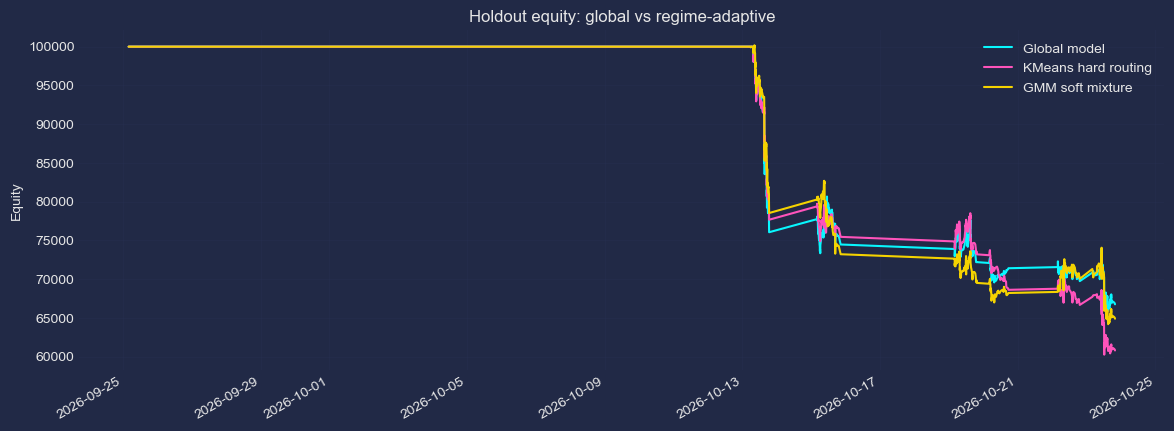

In [16]:
# =============================================================================
# BACKTEST GLOBAL VS ADAPTIVE
# =============================================================================
bt_signature = inspect.signature(backtest)
required_bt_args = {"bars", "signals", "config", "event_labels", "initial_capital"}
if not required_bt_args.issubset(set(bt_signature.parameters)):
    raise RuntimeError(
        "Текущий backtest_engine.backtest не имеет ожидаемого интерфейса event_labels. "
        f"Фактическая сигнатура: {bt_signature}. Не подменяю движок другим."
    )

bt_cfg = BacktestConfig(
    barrier_mode="event_labels",
    commission=COMMISSION,
    slippage=SLIPPAGE,
    entry_cutoff_hour=ENTRY_CUTOFF_HOUR,
    forced_close_hour=FORCED_CLOSE_HOUR,
    session_timezone=SESSION_TIMEZONE,
    position_fraction=1.0,
)

test_events = X_test_imp.index
event_labels_test = labels_test.reindex(test_events)[["upper", "lower", "t1"]].dropna()
test_events = event_labels_test.index
global_signals = pd.Series(
    np.where(pd.Series(global_prob_test, index=X_test_imp.index).reindex(test_events).to_numpy() >= 0.5, 1, -1),
    index=test_events, name="signal_global"
)
adaptive_signals = pd.Series(
    np.where(pd.Series(adaptive_prob_test, index=X_test_imp.index).reindex(test_events).to_numpy() >= 0.5, 1, -1),
    index=test_events, name="signal_adaptive"
)
gmm_signals = pd.Series(
    np.where(pd.Series(gmm_adaptive_prob_test, index=X_test_imp.index).reindex(test_events).to_numpy() >= 0.5, 1, -1),
    index=test_events, name="signal_gmm_adaptive"
)

global_bt = backtest(
    bars=bars,
    signals=global_signals,
    config=bt_cfg,
    event_labels=event_labels_test,
    initial_capital=INITIAL_CAPITAL,
)
adaptive_bt = backtest(
    bars=bars,
    signals=adaptive_signals,
    config=bt_cfg,
    event_labels=event_labels_test,
    initial_capital=INITIAL_CAPITAL,
)
gmm_adaptive_bt = backtest(
    bars=bars,
    signals=gmm_signals,
    config=bt_cfg,
    event_labels=event_labels_test,
    initial_capital=INITIAL_CAPITAL,
)

def metrics_dict(result, name):
    row = {"strategy": name}
    if isinstance(result.metrics, dict):
        row.update(result.metrics)
    row["trades_rows"] = len(result.trades)
    row["equity_final"] = float(result.equity.dropna().iloc[-1]) if len(result.equity.dropna()) else np.nan
    row["equity_return"] = row["equity_final"] / INITIAL_CAPITAL - 1 if np.isfinite(row["equity_final"]) else np.nan
    return row

backtest_comparison = pd.DataFrame([
    metrics_dict(global_bt, "global_catboost"),
    metrics_dict(adaptive_bt, "kmeans_hard_routing"),
    metrics_dict(gmm_adaptive_bt, "gmm_soft_mixture"),
])
display(backtest_comparison)
display(global_bt.diagnostics if isinstance(global_bt.diagnostics, dict) else pd.DataFrame([global_bt.diagnostics]))
display(adaptive_bt.diagnostics if isinstance(adaptive_bt.diagnostics, dict) else pd.DataFrame([adaptive_bt.diagnostics]))
display(gmm_adaptive_bt.diagnostics if isinstance(gmm_adaptive_bt.diagnostics, dict) else pd.DataFrame([gmm_adaptive_bt.diagnostics]))

fig, ax = plt.subplots(figsize=(14, 5))
global_bt.equity.plot(ax=ax, label="Global model")
adaptive_bt.equity.plot(ax=ax, label="KMeans hard routing")
gmm_adaptive_bt.equity.plot(ax=ax, label="GMM soft mixture")
ax.set_title("Holdout equity: global vs regime-adaptive")
ax.set_ylabel("Equity")
ax.grid(True, alpha=0.25)
ax.legend()
plt.show()


## 12. Аудит сделок

Здесь анализируем, **почему** стратегия теряет или зарабатывает: направление, режим на момент сигнала, время суток, причина выхода, удержание, gross/net PnL и fees. Поля зависят от версии движка, поэтому ячейка сначала покажет фактические колонки и использует только доступные.

MAE/MFE нельзя достоверно восстановить только из итоговой строки сделки: для этого нужны entry/exit timestamps и OHLC на всём пути сделки. Если таких данных достаточно, следующая ячейка рассчитывает приближённые MAE/MFE по барам между входом и выходом; при отсутствии необходимых полей эти показатели останутся NaN.

In [18]:
# =============================================================================
# TRADE-LEVEL DIAGNOSTICS
# =============================================================================
def enrich_trades(result, name, regime_by_signal, bars_frame):
    trades = result.trades.copy()
    if trades.empty:
        print(f"{name}: no trades")
        return trades

    trades["strategy"] = name
    print(f"{name} trade columns:", list(trades.columns))

    # Attach regime by signal timestamp, if the engine preserves signal_time.
    if "signal_time" in trades.columns:
        sig_ts = pd.to_datetime(trades["signal_time"], errors="coerce", utc=True)
        lookup = regime_by_signal.copy()
        lookup.index = pd.to_datetime(lookup.index, errors="coerce", utc=True)
        trades["regime"] = sig_ts.map(lookup)

    # Normalize common names from different engine versions.
    aliases = {
        "entry_time": ("entry_time", "entry_ts", "entry_timestamp"),
        "exit_time": ("exit_time", "exit_ts", "exit_timestamp"),
        "entry_price": ("entry", "entry_price", "entry_px"),
        "exit_price": ("exit", "exit_price", "exit_px"),
        "net_pnl": ("net_pnl", "pnl_net", "profit"),
        "gross_pnl": ("gross_pnl", "pnl_gross"),
        "fees": ("fees", "commission", "fees_total"),
        "reason": ("reason", "exit_reason", "exit_type"),
        "side": ("side_name", "side", "direction"),
    }
    for target, candidates in aliases.items():
        if target not in trades.columns:
            src = next((c for c in candidates if c in trades.columns), None)
            if src is not None:
                trades[target] = trades[src]

    if "entry_time" in trades:
        trades["entry_time"] = pd.to_datetime(trades["entry_time"], errors="coerce", utc=True)
        trades["entry_hour_utc"] = trades["entry_time"].dt.hour
    if "exit_time" in trades:
        trades["exit_time"] = pd.to_datetime(trades["exit_time"], errors="coerce", utc=True)
    if {"entry_time", "exit_time"}.issubset(trades.columns):
        trades["holding_minutes"] = (
            (trades["exit_time"] - trades["entry_time"]).dt.total_seconds() / 60.0
        )

    # Approximate path excursion from available OHLC bars.
    b = bars_frame.copy()
    if "bar_ts" not in b:
        if "close_time" in b:
            b["bar_ts"] = b["close_time"]
        else:
            b["bar_ts"] = b.index
    b["bar_ts"] = pd.to_datetime(b["bar_ts"], errors="coerce", utc=True)
    ren = {c: c.upper() for c in ("open", "high", "low", "close") if c in b.columns}
    b = b.rename(columns=ren).dropna(subset=["bar_ts"]).sort_values("bar_ts").drop_duplicates("bar_ts")
    if {"HIGH", "LOW"}.issubset(b.columns) and {"entry_time", "exit_time", "entry_price", "side"}.issubset(trades.columns):
        b = b.set_index("bar_ts")
        maes, mfes = [], []
        for _, tr in trades.iterrows():
            start, end, entry = tr["entry_time"], tr["exit_time"], tr["entry_price"]
            side_raw = str(tr["side"]).upper()
            side = 1 if side_raw in ("1", "LONG", "BUY") else (-1 if side_raw in ("-1", "SHORT", "SELL") else 0)
            if pd.isna(start) or pd.isna(end) or pd.isna(entry) or side == 0:
                maes.append(np.nan); mfes.append(np.nan); continue
            path = b.loc[(b.index >= start) & (b.index <= end)]
            if path.empty:
                maes.append(np.nan); mfes.append(np.nan); continue
            if side == 1:
                mae = (float(path["LOW"].min()) / float(entry)) - 1.0
                mfe = (float(path["HIGH"].max()) / float(entry)) - 1.0
            else:
                mae = 1.0 - (float(path["HIGH"].max()) / float(entry))
                mfe = 1.0 - (float(path["LOW"].min()) / float(entry))
            maes.append(mae); mfes.append(mfe)
        trades["mae_pct_approx"] = maes
        trades["mfe_pct_approx"] = mfes
    return trades

global_trades = enrich_trades(global_bt, "global", regime_test, bars)
adaptive_trades = enrich_trades(adaptive_bt, "kmeans_hard", regime_test, bars)
gmm_trades = enrich_trades(gmm_adaptive_bt, "gmm_soft", gmm_test_regime, bars)
all_trades = pd.concat([global_trades, adaptive_trades, gmm_trades], ignore_index=True, sort=False)

display(all_trades.tail(10))


global trade columns: ['signal_time', 'entry_time', 'exit_time', 'side', 'side_name', 'qty', 'entry', 'exit', 'entry_notional', 'exit_notional', 'target', 'tp', 'sl', 'gross_pnl', 'fees', 'net_pnl', 'reason', 'bars_held', 'strategy']
kmeans_hard trade columns: ['signal_time', 'entry_time', 'exit_time', 'side', 'side_name', 'qty', 'entry', 'exit', 'entry_notional', 'exit_notional', 'target', 'tp', 'sl', 'gross_pnl', 'fees', 'net_pnl', 'reason', 'bars_held', 'strategy']
gmm_soft trade columns: ['signal_time', 'entry_time', 'exit_time', 'side', 'side_name', 'qty', 'entry', 'exit', 'entry_notional', 'exit_notional', 'target', 'tp', 'sl', 'gross_pnl', 'fees', 'net_pnl', 'reason', 'bars_held', 'strategy']


,signal_time,entry_time,exit_time,side,side_name,qty,entry,exit,entry_notional,exit_notional,...,reason,bars_held,strategy,regime,entry_price,exit_price,entry_hour_utc,holding_minutes,mae_pct_approx,mfe_pct_approx
1932,2026-10-09 13:47:00+00:00,2026-10-09 13:56:45+00:00,2026-10-09 15:00:58+00:00,1,LONG,184.720756,237.62376,239.386725,43894.040531,44219.696799,...,take_profit,7,gmm_soft,1,237.62376,239.386725,13,64.216667,-0.000100,0.010000
1933,2026-10-09 15:00:58+00:00,2026-10-09 15:01:01+00:00,2026-10-09 15:02:25+00:00,-1,SHORT,184.816928,238.97610,239.823980,44166.828556,44323.531133,...,reverse,1,gmm_soft,1,238.97610,239.823980,15,1.400000,-0.007632,-0.000100
1934,2026-10-09 15:01:01+00:00,2026-10-09 15:02:25+00:00,2026-10-09 15:05:15+00:00,1,LONG,183.288726,239.82398,239.576040,43957.031764,43911.587157,...,reverse,2,gmm_soft,1,239.82398,239.576040,15,2.833333,-0.000934,0.004070
1935,2026-10-09 15:04:35+00:00,2026-10-09 15:05:15+00:00,2026-10-09 15:30:11+00:00,-1,SHORT,183.068666,239.57604,240.024000,43858.865986,43940.873425,...,reverse,2,gmm_soft,1,239.57604,240.024000,15,24.933333,-0.005109,-0.000100
1936,2026-10-09 15:13:45+00:00,2026-10-09 15:30:11+00:00,2026-10-09 15:57:32+00:00,1,LONG,182.165861,240.02400,240.175980,43724.178703,43751.864270,...,reverse,2,gmm_soft,0,240.02400,240.175980,15,27.350000,-0.002600,0.001567
1937,2026-10-09 15:34:31+00:00,2026-10-09 15:57:32+00:00,2026-10-09 16:25:11+00:00,-1,SHORT,181.947331,240.17598,239.823980,43699.378645,43635.333184,...,reverse,2,gmm_soft,0,240.17598,239.823980,15,27.650000,-0.000933,0.003231
1938,2026-10-09 16:05:00+00:00,2026-10-09 16:25:11+00:00,2026-10-09 17:12:14+00:00,1,LONG,182.262938,239.82398,239.976000,43711.023278,43738.730890,...,reverse,3,gmm_soft,0,239.82398,239.976000,16,47.050000,-0.003436,0.002402
1939,2026-10-09 17:00:25+00:00,2026-10-09 17:12:14+00:00,2026-10-09 17:12:14+00:00,-1,SHORT,182.044292,239.97600,239.175176,43686.261038,43540.475513,...,take_profit,1,gmm_soft,0,239.97600,239.175176,17,0.000000,-0.000933,0.004067
1940,2026-10-09 17:12:14+00:00,2026-10-09 17:13:25+00:00,2026-10-09 17:13:25+00:00,1,LONG,183.160389,239.02390,238.311562,43779.710520,43649.238365,...,stop_loss,1,gmm_soft,0,239.02390,238.311562,17,0.000000,-0.004284,-0.000100
1941,2026-10-09 17:13:25+00:00,2026-10-09 17:21:17+00:00,2026-10-09 17:36:43+00:00,1,LONG,182.854118,238.42384,237.499028,43596.780996,43427.675243,...,stop_loss,2,gmm_soft,0,238.42384,237.499028,17,15.433333,-0.005133,0.000739


In [19]:
# =============================================================================
# GROUPED TRADE REPORTS
# =============================================================================
if all_trades.empty:
    print("Нет сделок для анализа.")
else:
    pnl_col = "net_pnl" if "net_pnl" in all_trades.columns else None
    group_candidates = [
        c for c in ("strategy", "regime", "side", "reason", "entry_hour_utc")
        if c in all_trades.columns
    ]
    if pnl_col:
        def trade_stats(g):
            pnl = pd.to_numeric(g[pnl_col], errors="coerce").dropna()
            wins = pnl[pnl > 0]
            losses = pnl[pnl < 0]
            gross_profit = wins.sum()
            gross_loss = abs(losses.sum())
            return pd.Series({
                "trades": len(pnl),
                "total_net_pnl": pnl.sum(),
                "avg_net_pnl": pnl.mean(),
                "median_net_pnl": pnl.median(),
                "win_rate": (pnl > 0).mean(),
                "avg_win": wins.mean() if len(wins) else np.nan,
                "avg_loss": losses.mean() if len(losses) else np.nan,
                "profit_factor": gross_profit / gross_loss if gross_loss > 0 else np.inf,
            })
        for cols in (["strategy"], [c for c in ["strategy", "regime"] if c in all_trades], [c for c in ["strategy", "side"] if c in all_trades], [c for c in ["strategy", "reason"] if c in all_trades], [c for c in ["strategy", "entry_hour_utc"] if c in all_trades]):
            if cols:
                print("\nGROUP BY:", cols)
                display(all_trades.groupby(cols, dropna=False).apply(trade_stats).reset_index())
    if "holding_minutes" in all_trades:
        display(all_trades.groupby("strategy")["holding_minutes"].describe())
    if "mae_pct_approx" in all_trades and "mfe_pct_approx" in all_trades:
        display(all_trades.groupby("strategy")[["mae_pct_approx", "mfe_pct_approx"]].agg(["count", "mean", "median", "std"]))



GROUP BY: ['strategy']


C:\Users\Сергей Кравцов\AppData\Local\Temp\ipykernel_2820\2428393447.py:32: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  display(all_trades.groupby(cols, dropna=False).apply(trade_stats).reset_index())


,strategy,trades,total_net_pnl,avg_net_pnl,median_net_pnl,win_rate,avg_win,avg_loss,profit_factor
0,global,640.0,-59168.872865,-92.451364,-39.984392,0.471875,190.120201,-344.926549,0.492484
1,gmm_soft,652.0,-56624.539430,-86.847453,-31.372459,0.489264,190.576161,-352.607612,0.517754
2,kmeans_hard,650.0,-56362.278354,-86.711197,-50.949796,0.475385,207.132328,-352.979964,0.531743



GROUP BY: ['strategy', 'regime']


C:\Users\Сергей Кравцов\AppData\Local\Temp\ipykernel_2820\2428393447.py:32: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  display(all_trades.groupby(cols, dropna=False).apply(trade_stats).reset_index())


,strategy,regime,trades,total_net_pnl,avg_net_pnl,median_net_pnl,win_rate,avg_win,avg_loss,profit_factor
0,global,0,639.0,-58814.407403,-92.041326,-39.912089,0.472613,190.120201,-344.898244,0.493986
1,global,2,1.0,-354.465461,-354.465461,-354.465461,0.000000,NaN,-354.465461,0.000000
2,gmm_soft,0,527.0,-40375.496747,-76.613846,15.468386,0.516129,189.093007,-360.034489,0.560222
3,gmm_soft,1,125.0,-16249.042684,-129.992341,-172.542590,0.376000,199.159519,-328.327437,0.365508
4,kmeans_hard,0,649.0,-55969.687882,-86.239889,-49.360522,0.476117,207.132328,-352.863462,0.533483
5,kmeans_hard,2,1.0,-392.590471,-392.590471,-392.590471,0.000000,NaN,-392.590471,0.000000


... (7 outputs left out)

C:\Users\Сергей Кравцов\AppData\Local\Temp\ipykernel_2820\2428393447.py:32: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  display(all_trades.groupby(cols, dropna=False).apply(trade_stats).reset_index())


,strategy,entry_hour_utc,trades,total_net_pnl,avg_net_pnl,median_net_pnl,win_rate,avg_win,avg_loss,profit_factor
0,global,4,56.0,-2776.728604,-49.584439,64.914232,0.589286,178.379056,-376.662497,0.679481
1,global,5,24.0,-1034.847517,-43.118647,13.819415,0.541667,168.421014,-293.120063,0.679049
2,global,6,22.0,-839.740531,-38.170024,52.323077,0.545455,188.102610,-309.697185,0.728851
3,global,7,64.0,-11051.300064,-172.676563,-244.373077,0.343750,196.100511,-365.845507,0.280772
4,global,8,51.0,-5561.790664,-109.054719,-100.138784,0.431373,153.134935,-307.957215,0.377232
5,global,9,38.0,-3708.246554,-97.585436,-113.415311,0.394737,139.963262,-252.508500,0.361494
6,global,10,19.0,-1614.132779,-84.954357,17.977946,0.526316,182.475087,-382.098183,0.530623
7,global,11,62.0,-6831.358246,-110.183198,-88.342679,0.451613,162.994102,-335.152738,0.400505
8,global,12,24.0,-2761.704494,-115.071021,-230.169034,0.375000,276.595049,-350.070662,0.474067
9,global,13,101.0,-10899.206201,-107.912933,-73.781606,0.465347,264.971381,-432.460391,0.533282


,count,mean,std,min,25%,50%,75%,max
strategy,,,,,,,,
global,640.0,13.040521,39.427664,0.0,0.066667,1.650000,10.429167,608.716667
gmm_soft,652.0,17.260941,94.129148,0.0,0.100000,2.291667,12.150000,2033.750000
kmeans_hard,650.0,21.123231,163.018402,0.0,0.087500,2.200000,13.658333,3515.050000


mae_pct_approx                               mfe_pct_approx  \
                     count      mean    median       std          count   
strategy                                                                  
global                 640 -0.004029 -0.004051  0.003025            640   
gmm_soft               652 -0.003902 -0.003490  0.003019            652   
kmeans_hard            650 -0.003967 -0.003539  0.002948            650   

                                           
                 mean    median       std  
strategy                                   
global       0.003744  0.003360  0.002807  
gmm_soft     0.003737  0.003836  0.002676  
kmeans_hard  0.003705  0.003329  0.002776

## 13. Диагностика торговых правил и confidence threshold

Сравниваем вероятностные пороги 0.50/0.55/0.60: при `p_up >= threshold` открываем LONG, при `p_up <= 1-threshold` — SHORT, иначе пропускаем событие. Это помогает проверить, не ухудшает ли результат торговля слабых прогнозов.

**Не выбирай лучший порог по этому holdout и не объявляй его финальным.** Если какой-то вариант выглядит лучше, порог нужно подбирать на внутренней validation-части development периода, затем один раз проверить на нетронутом holdout. Правила выхода и риск-менеджмент следует исследовать отдельным экспериментом после диагностики сделок.

In [20]:
# =============================================================================
# CONFIDENCE FILTER SENSITIVITY (DIAGNOSTIC ONLY)
# =============================================================================
threshold_rows = []
prob_series_global = pd.Series(global_prob_test, index=X_test_imp.index)
prob_series_adaptive = pd.Series(adaptive_prob_test, index=X_test_imp.index)
prob_series_gmm = pd.Series(gmm_adaptive_prob_test, index=X_test_imp.index)

for model_name, probs in (("global", prob_series_global), ("kmeans_hard", prob_series_adaptive), ("gmm_soft", prob_series_gmm)):
    for threshold in (0.50, 0.55, 0.60, 0.65):
        # Trade only when probability is sufficiently far from 0.5.
        sig = pd.Series(0, index=probs.index, dtype=int, name="signal")
        sig.loc[probs >= threshold] = 1
        sig.loc[probs <= 1.0 - threshold] = -1
        sig = sig.reindex(event_labels_test.index)
        sig = sig.loc[sig != 0]
        row = {
            "model": model_name,
            "threshold": threshold,
            "eligible_events": len(probs),
            "signals_kept": len(sig),
            "signal_coverage": len(sig) / len(probs) if len(probs) else np.nan,
        }
        if len(sig):
            res = backtest(
                bars=bars,
                signals=sig,
                config=bt_cfg,
                event_labels=event_labels_test.reindex(sig.index),
                initial_capital=INITIAL_CAPITAL,
            )
            row.update(res.metrics if isinstance(res.metrics, dict) else {})
            row["trade_rows"] = len(res.trades)
            row["final_equity"] = float(res.equity.dropna().iloc[-1]) if len(res.equity.dropna()) else np.nan
        threshold_rows.append(row)

threshold_sensitivity = pd.DataFrame(threshold_rows)
display(threshold_sensitivity)


,model,threshold,eligible_events,signals_kept,signal_coverage,total_return,sharpe,sortino,max_drawdown,calmar,win_rate,profit_factor,avg_win,avg_loss,expectancy,turnover,trades,trade_rows,final_equity
0,global,0.50,1476,1476,1.000000,-0.591689,-1.185106,-0.847833,-0.593330,-0.997234,0.471875,0.492484,190.120201,344.926549,-92.451364,8.489770e+07,640,640,40831.127135
1,global,0.55,1476,1251,0.847561,-0.480076,-0.905212,-0.652586,-0.484581,-0.990703,0.487896,0.566295,239.252391,402.515259,-89.399571,7.983613e+07,537,537,51992.430265
2,global,0.60,1476,1021,0.691734,-0.407347,-0.772291,-0.525357,-0.417804,-0.974972,0.493304,0.589609,264.812434,437.261016,-90.925676,6.969435e+07,448,448,59265.297169
3,global,0.65,1476,787,0.533198,-0.299183,-0.576602,-0.354773,-0.315079,-0.949548,0.512465,0.649133,299.196168,484.486184,-82.876114,6.080907e+07,361,361,70081.722731
4,kmeans_hard,0.50,1476,1476,1.000000,-0.563623,-1.115279,-0.841758,-0.563623,-1.000000,0.475385,0.531743,207.132328,352.979964,-86.711197,9.064091e+07,650,650,43637.721646
5,kmeans_hard,0.55,1476,1272,0.861789,-0.492058,-0.943234,-0.693246,-0.492058,-1.000000,0.479860,0.565338,233.572681,381.160537,-86.174720,8.491140e+07,571,571,50794.235140
6,kmeans_hard,0.60,1476,1041,0.705285,-0.406824,-0.783537,-0.538772,-0.408864,-0.995010,0.496829,0.603836,263.865707,431.474136,-86.009309,7.570825e+07,473,473,59317.596821
7,kmeans_hard,0.65,1476,829,0.561653,-0.362266,-0.749958,-0.461428,-0.370203,-0.978560,0.489899,0.599481,279.497381,447.767895,-91.481371,6.497569e+07,396,396,63773.377064
8,gmm_soft,0.50,1476,1476,1.000000,-0.566245,-1.121584,-0.807386,-0.569248,-0.994726,0.489264,0.517754,190.576161,352.607612,-86.847453,9.073664e+07,652,652,43375.460570
9,gmm_soft,0.55,1476,1231,0.834011,-0.475104,-0.905836,-0.634805,-0.480176,-0.989436,0.505618,0.545580,211.264280,396.029248,-88.970723,7.722346e+07,534,534,52489.634034


## 14. Диагностика управления капиталом и расписания выхода

Этот блок не подбирает параметры автоматически. Он показывает, насколько результаты зависят от размера позиции и внутридневных ограничений:
- `position_fraction`: 25%, 50%, 75%, 100% капитала;
- варианты `entry_cutoff_hour`;
- варианты `forced_close_hour`.

Это анализ чувствительности на том же holdout, поэтому нельзя выбрать лучший вариант по этой таблице и считать результат независимой проверкой. Перспективные варианты нужно затем сравнить на внутренних validation / walk-forward окнах.

In [21]:
# =============================================================================
# CAPITAL MANAGEMENT + EXECUTION-RULE SENSITIVITY (DIAGNOSTIC ONLY)
# =============================================================================
management_rows = []
signal_sets = {
    "global": global_signals,
    "kmeans_hard": adaptive_signals,
    "gmm_soft": gmm_signals,
}
for model_name, sig_base in signal_sets.items():
    for fraction in (0.25, 0.50, 0.75, 1.00):
        for cutoff_hour, close_hour in ((20, 22), (21, 23), (22, 23)):
            cfg = BacktestConfig(
                barrier_mode="event_labels",
                commission=COMMISSION,
                slippage=SLIPPAGE,
                entry_cutoff_hour=cutoff_hour,
                forced_close_hour=close_hour,
                session_timezone=SESSION_TIMEZONE,
                position_fraction=fraction,
            )
            res = backtest(
                bars=bars,
                signals=sig_base,
                config=cfg,
                event_labels=event_labels_test.reindex(sig_base.index),
                initial_capital=INITIAL_CAPITAL,
            )
            row = {
                "model": model_name,
                "position_fraction": fraction,
                "entry_cutoff_hour": cutoff_hour,
                "forced_close_hour": close_hour,
                "trade_rows": len(res.trades),
                "final_equity": float(res.equity.dropna().iloc[-1]) if len(res.equity.dropna()) else np.nan,
            }
            if isinstance(res.metrics, dict):
                row.update(res.metrics)
            management_rows.append(row)

management_sensitivity = pd.DataFrame(management_rows)
display(management_sensitivity.sort_values(["model", "position_fraction", "entry_cutoff_hour"]))


,model,position_fraction,entry_cutoff_hour,forced_close_hour,trade_rows,final_equity,total_return,sharpe,sortino,max_drawdown,calmar,win_rate,profit_factor,avg_win,avg_loss,expectancy,turnover,trades
0,global,0.25,20,22,615,80555.943637,-0.194441,-1.170151,-0.819043,-0.197311,-0.985454,0.469919,0.491061,64.917005,117.193469,-31.616352,2.760763e+07,615
1,global,0.25,21,23,633,80130.716916,-0.198693,-1.185603,-0.841383,-0.199697,-0.994971,0.470774,0.490593,64.212863,116.431989,-31.389073,2.837467e+07,633
2,global,0.25,22,23,640,80045.416912,-0.199546,-1.186232,-0.848170,-0.200360,-0.995937,0.471875,0.491464,63.856476,116.092423,-31.179036,2.870722e+07,640
3,global,0.50,20,22,615,64835.270712,-0.351647,-1.169804,-0.818948,-0.356246,-0.987092,0.469919,0.490663,117.216058,211.779663,-57.178422,4.976115e+07,615
4,global,0.50,21,23,633,64151.658127,-0.358483,-1.185239,-0.841279,-0.360075,-0.995579,0.470774,0.490563,115.839625,210.055374,-56.632452,5.107779e+07,633
5,global,0.50,22,23,640,64014.908755,-0.359851,-1.185857,-0.848058,-0.361148,-0.996409,0.471875,0.491765,115.294388,209.479279,-56.226705,5.171292e+07,640
6,global,0.75,20,22,615,52136.313804,-0.478637,-1.169456,-0.818852,-0.484157,-0.988598,0.469919,0.490324,159.329800,288.067480,-77.827132,6.751968e+07,615
7,global,0.75,21,23,633,51312.794327,-0.486872,-1.184873,-0.841174,-0.488763,-0.996132,0.470774,0.490583,157.339253,285.296427,-76.915017,6.922795e+07,633
8,global,0.75,22,23,640,51148.519714,-0.488515,-1.185482,-0.847946,-0.490063,-0.996841,0.471875,0.492110,156.733750,284.571222,-76.330438,7.014149e+07,640
9,global,1.00,20,22,615,41887.425320,-0.581126,-1.169108,-0.818755,-0.587012,-0.989973,0.469919,0.490029,193.218164,349.547927,-94.491991,8.173824e+07,615


## 15. Интерпретация и критерии решения

Смотри не только на итоговую доходность.

1. **Adaptive vs global:** улучшились ли net return и max drawdown одновременно? Не получен ли результат ценой резкого сокращения количества сделок?
2. **По режимам:** достаточно ли событий в каждом режиме; отличается ли средний PnL, win rate и profit factor?
3. **Качество прогноза:** adaptive должен оцениваться на тех же holdout событиях, что и global; учитывай log loss и Brier, а не только accuracy.
4. **Сделки:** есть ли режимы/часы/направления с систематическим отрицательным ожиданием? Часто ли сделки закрываются стопом, forced close или reverse?
5. **MAE/MFE:** если прибыльные сделки регулярно показывают большой MFE, но закрываются с малой прибылью, можно отдельно проверить выходы. Если MAE быстро достигает стопа, исследовать фильтр входа/размер позиции. MAE/MFE здесь приблизительны и зависят от доступности OHLC и временных меток.
6. **Риск управления капиталом:** только после выявления закономерности сравнивай фиксированную долю капитала, волатильностное масштабирование и лимиты риска. Нельзя оптимизировать одновременно модель, режимы, TP/SL и sizing — иначе не поймём источник улучшения.
7. **Обобщаемость:** следующий шаг — expanding walk-forward с несколькими последовательными тестовыми окнами. Один holdout недостаточен для вывода об устойчивой прибыльности.

Эксперимент считается перспективным, если преимущество adaptive повторяется на нескольких независимых walk-forward окнах после комиссий/проскальзывания, при приемлемой просадке и без катастрофически малого числа сделок.


In [22]:
# =============================================================================
# EXPORT RESEARCH ARTIFACTS (OPTIONAL)
# =============================================================================
from pathlib import Path
OUT_DIR = Path("research/afml/mark_6/results")
OUT_DIR.mkdir(parents=True, exist_ok=True)

cluster_diagnostics_df.to_csv(OUT_DIR / "cluster_diagnostics.csv", index=False)
regime_counts.to_csv(OUT_DIR / "regime_counts.csv")
classification_comparison.to_csv(OUT_DIR / "classification_comparison.csv", index=False)
backtest_comparison.to_csv(OUT_DIR / "backtest_comparison.csv", index=False)
all_trades.to_csv(OUT_DIR / "trade_audit.csv", index=False)
threshold_sensitivity.to_csv(OUT_DIR / "threshold_sensitivity.csv", index=False)
management_sensitivity.to_csv(OUT_DIR / "management_sensitivity.csv", index=False)

print("Saved to:", OUT_DIR.resolve())
print("Files:", sorted(p.name for p in OUT_DIR.iterdir()))


Saved to: C:\Users\Сергей Кравцов\regime_research_outputs
Files: ['backtest_comparison.csv', 'classification_comparison.csv', 'cluster_diagnostics.csv', 'management_sensitivity.csv', 'regime_counts.csv', 'threshold_sensitivity.csv', 'trade_audit.csv']
